<a href="https://colab.research.google.com/github/razokiyassine/Network-Intrusion-Detection/blob/main/tp_Random%20_Forest_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (classification_report, confusion_matrix,
    ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score)
import time
X, y = make_classification(n_samples=1500, n_features=12, n_informative=7,
    n_redundant=3, weights=[0.80, 0.20], class_sep=0.9,
    flip_y=0.025, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)
print('Répartition:', pd.Series(y).value_counts())
print('Train/Test:', X_train.shape, X_test.shape)


Répartition: 0    1192
1     308
Name: count, dtype: int64
Train/Test: (1125, 12) (375, 12)


In [2]:
arbre = DecisionTreeClassifier(random_state=42)
arbre.fit(X_train, y_train)
pred_arbre = arbre.predict(X_test)
print(classification_report(y_test, pred_arbre, zero_division=0))
print('Profondeur :', arbre.get_depth(), 'Feuilles :', arbre.get_n_leaves())
# TODO : entraîner un deuxième arbre avec max_depth=5 et comparer les scores


              precision    recall  f1-score   support

           0       0.90      0.93      0.91       298
           1       0.68      0.60      0.63        77

    accuracy                           0.86       375
   macro avg       0.79      0.76      0.77       375
weighted avg       0.85      0.86      0.86       375

Profondeur : 17 Feuilles : 81


              precision    recall  f1-score   support

           0       0.92      0.98      0.95       298
           1       0.91      0.65      0.76        77

    accuracy                           0.91       375
   macro avg       0.91      0.82      0.85       375
weighted avg       0.91      0.91      0.91       375

Score OOB : 0.9164444444444444


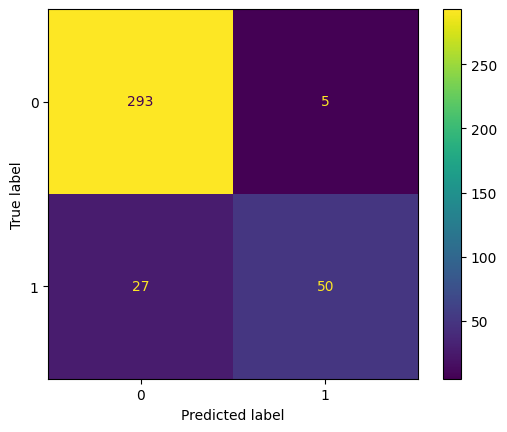

In [3]:
rf = RandomForestClassifier(n_estimators=100, random_state=42,
    bootstrap=True, oob_score=True, n_jobs=-1)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
print(classification_report(y_test, pred_rf, zero_division=0))
print('Score OOB :', rf.oob_score_)
ConfusionMatrixDisplay.from_predictions(y_test, pred_rf)
plt.show()
# TODO : afficher la prédiction des 5 premiers arbres sur X_test[:1]
# Indice : rf.estimators_[i].predict(X_test[:1])


In [4]:
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)
def eval_cv(modele):
    s = cross_validate(modele, X_train, y_train, cv=cv,
        scoring={'f1':'f1','recall':'recall','precision':'precision',
                 'accuracy':'accuracy'}, return_train_score=True)
    return {k: round(s['test_'+k].mean(), 4)
            for k in ['f1','recall','precision','accuracy']}
for n in [20, 100, 250]:
    print('n_estimators=', n, eval_cv(RandomForestClassifier(
        n_estimators=n, random_state=42, n_jobs=-1)))
# TODO : tester max_depth = [3, 6, 12, None]
# TODO : tester min_samples_leaf = [1, 3, 8]
# TODO : tester max_features = ['sqrt', 'log2', None]
# TODO : comparer criterion = ['gini', 'entropy']


n_estimators= 20 {'f1': np.float64(0.7343), 'recall': np.float64(0.6277), 'precision': np.float64(0.8847), 'accuracy': np.float64(0.9067)}
n_estimators= 100 {'f1': np.float64(0.7641), 'recall': np.float64(0.6751), 'precision': np.float64(0.8812), 'accuracy': np.float64(0.9147)}
n_estimators= 250 {'f1': np.float64(0.7689), 'recall': np.float64(0.6708), 'precision': np.float64(0.9012), 'accuracy': np.float64(0.9173)}


In [5]:
modeles = {
    'Arbre': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100,
        max_depth=12, random_state=42, n_jobs=-1),
    'SVM RBF': make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1))
}
resultats = []
for nom, modele in modeles.items():
    t0 = time.perf_counter()
    modele.fit(X_train, y_train)
    duree = time.perf_counter() - t0
    pred = modele.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0,1]).ravel()
    resultats.append([nom, accuracy_score(y_test,pred),
        precision_score(y_test,pred,zero_division=0),
        recall_score(y_test,pred,zero_division=0),
        f1_score(y_test,pred,zero_division=0),fp,fn,duree])
print(pd.DataFrame(resultats, columns=['Modèle','Accuracy','Precision',
    'Recall','F1','FP','FN','Temps (s)']).round(3))
# TODO : remplacer les réglages fixes par ceux sélectionnés en CV


          Modèle  Accuracy  Precision  Recall     F1  FP  FN  Temps (s)
0          Arbre     0.883      0.824   0.545  0.656   9  35      0.025
1  Random Forest     0.917      0.911   0.662  0.767   5  26      0.913
2        SVM RBF     0.936      0.982   0.701  0.818   1  23      0.083


In [6]:
importance = pd.Series(rf.feature_importances_,
    index=[f'feature_{i+1}' for i in range(X.shape[1])])
print(importance.sort_values(ascending=False))
# TODO : tracer un diagramme des importances
# TODO : proposer une méthode de permutation importance sur le test,
# puis discuter les limites d’interprétation


feature_8     0.172177
feature_10    0.125189
feature_1     0.117733
feature_7     0.107970
feature_5     0.092540
feature_3     0.084830
feature_9     0.079686
feature_11    0.077206
feature_12    0.050474
feature_6     0.038149
feature_2     0.028746
feature_4     0.025300
dtype: float64
